<a href="https://colab.research.google.com/github/aunyarit2005-hash/Comparative-Performance-Analysis-of-Image-Classification-Models-for-Malaria-Infected-Red-Blood-Cells/blob/main/Origin_moblienet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Mobilenet V2 Architecture

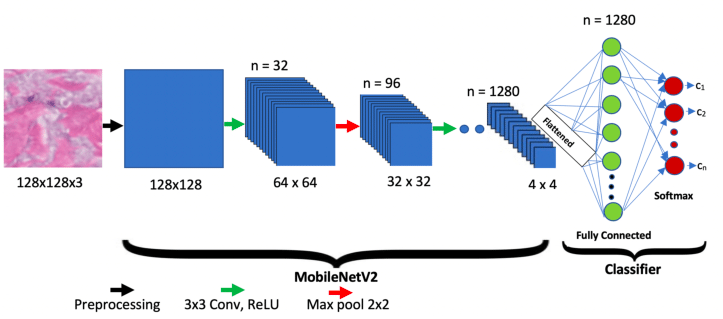

#🔌เเตก zip

In [ ]:
!unzip /content/Segment_Malariae-20260219T013031Z-1-001.zip -d /content/

Archive:  /content/Segment_Malariae-20260219T013031Z-1-001.zip
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225339.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225237.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225403.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225242.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225307.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225318.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225139.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225421.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225300.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225141.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 2251

# 📁 กำหนดเส้นทาง (Path) สำหรับข้อมูลภาพ Normal และ Malaria
รายละเอียดในโค้ด:
📂 ชุดข้อมูลฝึกสอน (Train): สำหรับให้โมเดลเรียนรู้ลักษณะของเซลล์

🧪 ชุดข้อมูลตรวจสอบ (Validation): สำหรับเช็กความแม่นยำระหว่างเทรน

🔍 ชุดข้อมูลทดสอบ (Test): สำหรับวัดผลหลังเทรนเสร็จว่าแยกแยะได้จริงไหม

In [ ]:
import os
file_path = '/content/Segment_Malariae'
# normal_train and malaria_train
normal_train = os.path.join(file_path, 'normal', 'train')
malaria_train = os.path.join(file_path, 'malaria', 'train')

# normal_Validation and malaria_Validation
normal_val = os.path.join(file_path, 'normal', 'val')
malaria_val = os.path.join(file_path, 'malaria', 'val')

# normal_test and malaria_test
normal_test = os.path.join(file_path, 'normal', 'test')
malaria_test = os.path.join(file_path, 'malaria', 'test')

# 🛠️ ฟังก์ชันสำหรับดึง Path ของไฟล์ภาพและกำหนด Label (ป้ายกำกับ)
🔍 การค้นหาไฟล์: ไล่ดูไฟล์ในโฟลเดอร์ที่กำหนดไว้ (Directory)

🖼️ กรองเฉพาะรูปภาพ: เลือกเอาเฉพาะไฟล์นามสกุล .jpg, .jpeg, .png, .gif เท่านั้น

🏷️ ติดป้ายกำกับ: จับคู่รูปภาพกับประเภท (เช่น Normal หรือ Malaria) เพื่อส่งค่ากลับไปเป็น List

In [ ]:
import os
import pandas as pd

# Define a function to get file paths and labels from a directory
def get_filepaths_and_labels(directory, label):
    filepaths = [] # Corrected: initialize as empty list
    labels = []    # Corrected: initialize as empty list
    # Ensure the directory exists before listing its contents
    if os.path.exists(directory):
        for filename in os.listdir(directory):
            # Check for common image file extensions
            if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.gif')):
                filepaths.append(os.path.join(directory, filename))
                labels.append(label)
    else:
        print(f"Warning: Directory not found: {directory}")
    return filepaths, labels

# สร้าง DataFrame สำหรับชุดข้อมูลฝึกสอน (Training Set)
🔗 รวมข้อมูล: เอาลิสต์รายชื่อไฟล์และป้ายกำกับ (Labels) จากทั้งฝั่ง Normal และ Malaria มารวมเข้าด้วยกัน

📝 จัดรูปแบบตาราง: นำข้อมูลทั้งหมดมาสร้างเป็น pd.DataFrame โดยแบ่งเป็นคอลัมน์ filepath (ที่อยู่ไฟล์) และ label (ประเภทของภาพ)

📈 ตรวจสอบจำนวน: แสดงยอดรวมของรูปภาพทั้งหมดที่มีอยู่ในชุด Train เพื่อเช็กความเรียบร้อย

In [ ]:
# --- Create Training DataFrame ---
# Get file paths and labels for normal training data
normal_train_filepaths, normal_train_labels = get_filepaths_and_labels(normal_train, 'normal')

# Get file paths and labels for malaria training data
malaria_train_filepaths, malaria_train_labels = get_filepaths_and_labels(malaria_train, 'malaria')

# Combine file paths and labels for the entire training set
train_filepaths = normal_train_filepaths + malaria_train_filepaths
train_labels = normal_train_labels + malaria_train_labels

# Create the training DataFrame
train_df = pd.DataFrame({'filepath': train_filepaths, 'label': train_labels})

print("✅ สร้าง DataFrame สำหรับ Training เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Train DataFrame: {len(train_df)}")

✅ สร้าง DataFrame สำหรับ Training เสร็จแล้ว!
จำนวนรูปภาพใน Train DataFrame: 1600


#🔍แสดงตัวอย่างข้อมูลใน Traning set ใน DataFrame

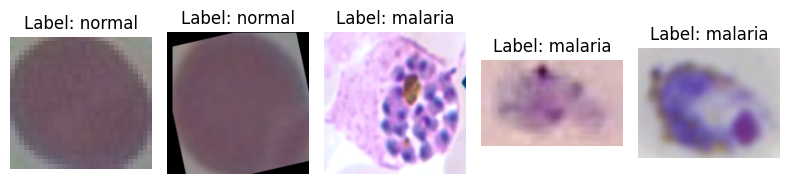

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = train_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 🧪 สร้าง DataFrame สำหรับชุดตรวจสอบ (Validation Set) และการสลับลำดับข้อมูล
🔄 เตรียมชุด Validation: ทำเหมือนกับชุด Train เลย คือดึง Path และ Label ของฝั่ง Normal และ Malaria มารวมเป็น val_df

🔀 สลับข้อมูล (Shuffle): ใช้คำสั่ง .sample(frac=1) เพื่อสลับตำแหน่งแถวในตารางให้มั่วซั่ว (Random) ป้องกันไม่ให้โมเดลเรียนรู้แบบท่องจำลำดับไฟล์

In [ ]:
normal_val_filepaths, normal_val_labels = get_filepaths_and_labels(normal_val, 'normal')

# Get file paths and labels for malaria validation data
malaria_val_filepaths, malaria_val_labels = get_filepaths_and_labels(malaria_val, 'malaria')

# Combine file paths and labels for the entire validation set
val_filepaths = normal_val_filepaths + malaria_val_filepaths
val_labels = normal_val_labels + malaria_val_labels

# Create the validation DataFrame
val_df = pd.DataFrame({'filepath': val_filepaths, 'label': val_labels})

# Shuffle the DataFrames to ensure randomness during training
train_df = train_df.sample(frac=1).reset_index(drop=True)
val_df = val_df.sample(frac=1).reset_index(drop=True)

print("✅ สร้าง DataFrame สำหรับ Validation เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Validation DataFrame: {len(val_df)}")

✅ สร้าง DataFrame สำหรับ Validation เสร็จแล้ว!
จำนวนรูปภาพใน Validation DataFrame: 200


# 🔍แสดงตัวอย่างข้อมูลใน Validation ใน DataFrame

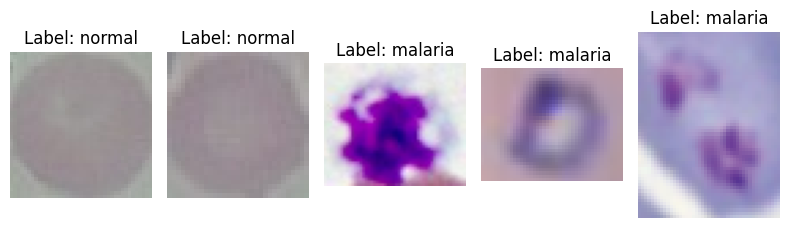

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = val_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 🔍สร้าง DataFrame สำหรับชุดข้อมูลทดสอบ (Test Set)

In [ ]:
# Get file paths and labels for normal test data
normal_test_filepaths, normal_test_labels = get_filepaths_and_labels(normal_test, 'normal')

# Get file paths and labels for malaria test data using the corrected path
malaria_test_filepaths, malaria_test_labels = get_filepaths_and_labels(malaria_test, 'malaria')

# Combine file paths and labels for the entire test set
test_filepaths = normal_test_filepaths + malaria_test_filepaths
test_labels = normal_test_labels + malaria_test_labels

# Create the test DataFrame
test_df = pd.DataFrame({'filepath': test_filepaths, 'label': test_labels})

# Shuffle the DataFrame to ensure randomness
test_df = test_df.sample(frac=1).reset_index(drop=True)

print(f"✅ สร้าง DataFrame สำหรับ Test เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Test DataFrame: {len(test_df)}")

✅ สร้าง DataFrame สำหรับ Test เสร็จแล้ว!
จำนวนรูปภาพใน Test DataFrame: 200


# 🔍แสดงตัวอย่างข้อมูลใน Test set ใน DataFrame

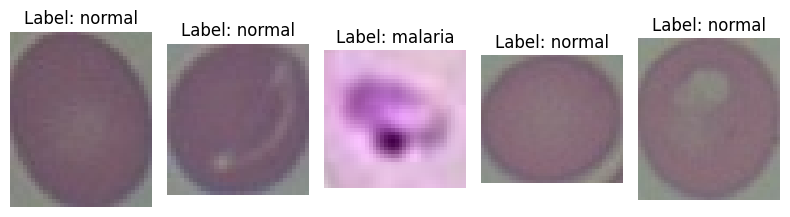

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = test_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 🧠 สร้างและตั้งค่าโมเดล Deep Learning (MobileNetV2)

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# --- 1. โหลดโมเดล MobileNetV2 ---
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    alpha=1.0,   # <---- ตัวควบคุม ความกว้าง ของ Network หรือจำนวน Channel ในแต่ละเลเยอร์ (โดยทั่วไปจะมีค่าให้เลือกเช่น 0.25, 0.50, 0.75 ไปจนถึง 1.0)
    weights='imagenet',
    pooling='avg', # <---- เปลี่ยนเป็น 'avg', 'min', 'max'
    classes=1000
)
# --- 2. ปิดสมองส่วนต้น (Freeze Base) ---
base_model.trainable = False

# --- 3. ต่อหัวใหม่ให้เหมาะกับงานเรา ---
x = base_model.output
x = Dropout(0.2)(x) # <---- สุ่มปิดข้อมูลบางส่วนกันมันจำข้อสอบ (Overfitting)
predictions = Dense(2, activation='softmax')(x) # <---- 2 คือจำนวนคลาส (Normal, Malaria)

# --- 4. รวมร่าง ---
model = Model(inputs=base_model.input, outputs=predictions)

# --- 5. ตั้งค่ากระบวนการเรียนรู้ (Compile) ---
model.compile(optimizer=Adam(learning_rate=0.00001), # ปรับ Learning rate  0.01, 0.001, 0.0001, 0.00001, 0.000001 ยิ่งน้อย train ยิ่งช้า
                                                    # คือการกำหนดว่า ในแต่ละก้าว โมเดลจะเรียนรู้ดีแค่ไหน
              loss='categorical_crossentropy',
              metrics=['accuracy'])

print("✅ สร้างโมเดลเสร็จแล้ว! พร้อมลุย!")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✅ สร้างโมเดลเสร็จแล้ว! พร้อมลุย!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#🖼️ เตรียม Data Generator และการตั้งค่า Early Stopping

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

# --- 1. เตรียมดูดรูป (Data Generator) ---
# Data Generator สำหรับ Training
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input, # แปลงค่าสีให้เหมาะกับ MobileNet
    shear_range=0.2,             # Shear transformations
    zoom_range=0.2,              # Zoom transformations
    horizontal_flip=True         # Horizontal flip
)
# Data Generator สำหรับ Validation
validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # แปลงค่าสีให้เหมาะกับ MobileNet
)

# --- 2. สร้างตัวส่งข้อมูล (Generator) จาก DataFrame ---

# Training Generator
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,      # ใช้ DataFrame ที่เราสร้างขึ้นมา
    x_col='filepath',        # ชื่อคอลัมน์ที่เก็บ path รูปภาพ
    y_col='label',           # ชื่อคอลัมน์ที่เก็บ class label
    target_size=(224, 224),  # บังคับขนาดรูปภาพ
    batch_size=32, # <---- จำนวนข้อมูลที่เข้าไปในtrainingในแต่ละครั้ง จำนวนตามเลขยกกำลังสอง 2^n เช่น 8, 16, 32, 64 ไปจนถึง 512
    class_mode='categorical' # เพราะมี 2 คลาส (Normal, Malaria)
)

# Validation Generator
validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df,        # ใช้ DataFrame ของ Validation Set
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# --- 3. ตั้งค่า Callbacks ---
# Early Stopping เพื่อหยุดการเทรนเมื่อ Validation Loss ไม่ลดลงอีกแล้ว
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
]

Found 1600 validated image filenames belonging to 2 classes.
Found 200 validated image filenames belonging to 2 classes.


#🚀 เริ่มขั้นตอนการฝึกสอนโมเดล (Model Training)

In [ ]:
# --- 4. เข้า model.fit ---
EPOCHS = 5 # <---- จำนวนรอบในการ trainmodel ยิ่งเยอะยิ่งนาน เเนะนำ 10 ถึง 20

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)

print("🎉 เทรนเสร็จแล้ว!")

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 102s 2s/step - accuracy: 0.4144 - loss: 1.0229 - val_accuracy: 0.5900 - val_loss: 0.8388
Epoch 2/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.4608 - loss: 0.9435 - val_accuracy: 0.6250 - val_loss: 0.7830
Epoch 3/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.5150 - loss: 0.8385 - val_accuracy: 0.6300 - val_loss: 0.7404
Epoch 4/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.5253 - loss: 0.7841 - val_accuracy: 0.6300 - val_loss: 0.7072
Epoch 5/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step - accuracy: 0.5686 - loss: 0.7468 - val_accuracy: 0.6400 - val_loss: 0.6733
🎉 เทรนเสร็จแล้ว!


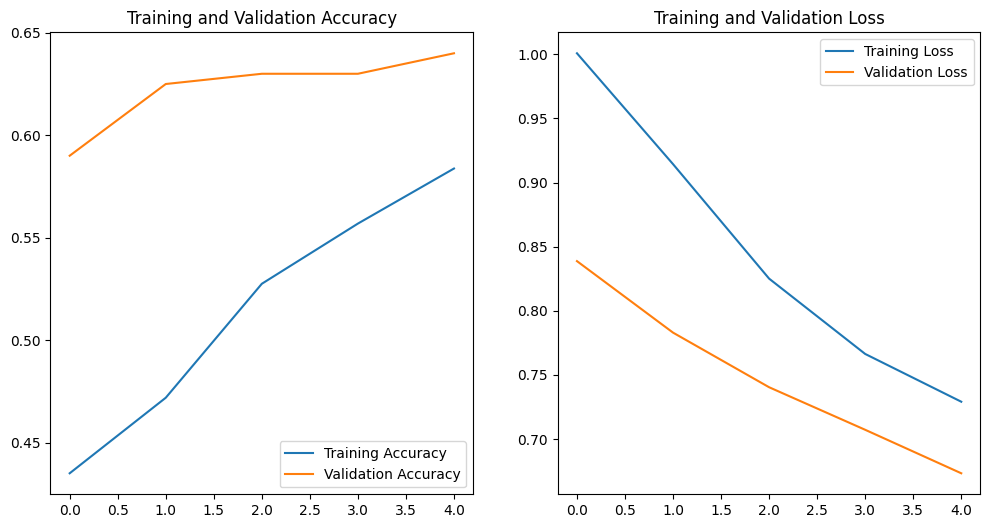

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 6))

    # กราฟ Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    # กราฟ Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')

    plt.show()

# เรียกใช้ฟังก์ชันซะ
plot_history(history)

# 📊 นำเข้า Library สำหรับประเมินผลและสร้าง Confusion Matrix ของชุดวัดผล

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

#📝 ตรวจสอบความแม่นยำย้อนหลังบนชุดข้อมูล Validation

In [ ]:
# ให้โมเดลลองทำข้อสอบชุด Validation ดูซิว่าจะได้เท่าไหร่
print("กำลังตรวจข้อสอบ")
val_loss, val_acc = model.evaluate(validation_generator)

print(f"Loss (ค่าความผิดพลาด): {val_loss:.4f}")
print(f"Accuracy (ความแม่น): {val_acc*100:.2f} %")

กำลังตรวจข้อสอบ
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.6391 - loss: 0.6496
Loss (ค่าความผิดพลาด): 0.6733
Accuracy (ความแม่น): 64.00 %


7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step


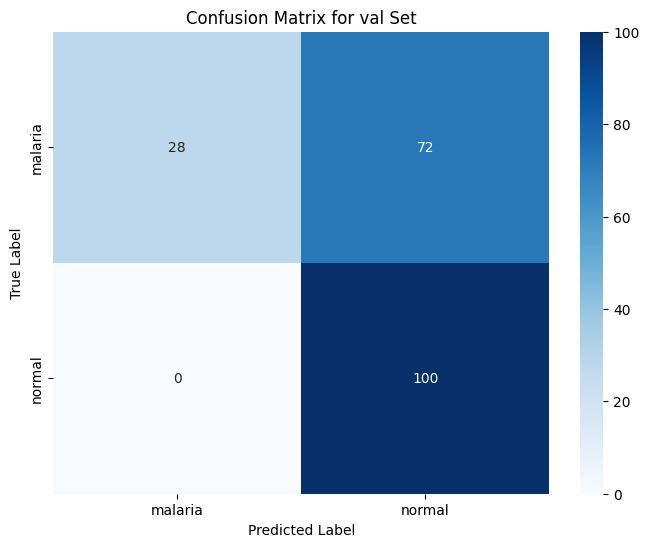

✅ สร้าง Confusion Matrix เสร็จแล้ว!


In [ ]:

validation_generator.reset()
predictions = model.predict(validation_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = validation_generator.classes
class_names = list(validation_generator.class_indices.keys())
cm = confusion_matrix(true_classes, predicted_classes)


plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for val Set')
plt.show()

print("✅ สร้าง Confusion Matrix เสร็จแล้ว!")

# 🏁 เตรียมข้อมูลTestและประเมินประสิทธิภาพของโมเดล (Model Evaluation)

In [ ]:
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # Normalize pixel values for MobileNetV2
)

# Test Generator
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,       # Use the newly created Test DataFrame
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # Important: do not shuffle test data for consistent evaluation
)

# --- Evaluate the Model ---
print("\nกำลังประเมินผลโมเดลด้วย Test Set...")
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test Loss (ค่าความผิดพลาดบน Test Set): {test_loss:.4f}")
print(f"Test Accuracy (ความแม่นบน Test Set): {test_acc*100:.2f} %")


Found 200 validated image filenames belonging to 2 classes.

กำลังประเมินผลโมเดลด้วย Test Set...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5706 - loss: 0.8028
Test Loss (ค่าความผิดพลาดบน Test Set): 0.7337
Test Accuracy (ความแม่นบน Test Set): 61.50 %


7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step


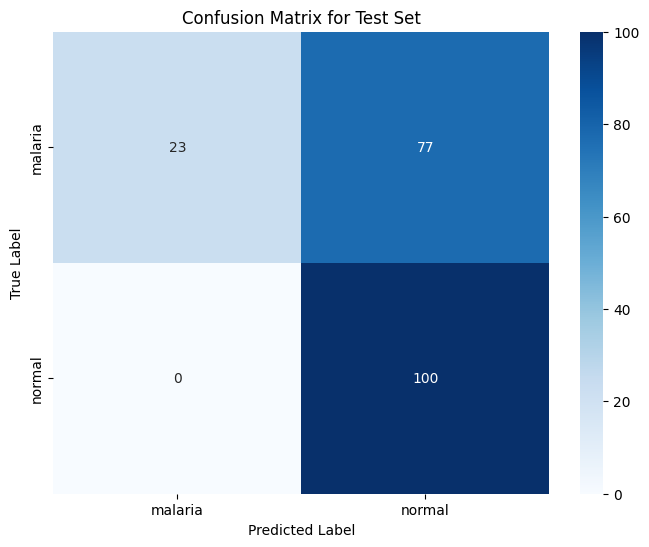

✅ สร้าง Confusion Matrix เสร็จแล้ว!


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Get true labels and predictions ---

# Reset the test_generator to ensure predictions start from the beginning
test_generator.reset()

# Get predictions from the model
predictions = model.predict(test_generator)

# Get predicted class labels (index of the highest probability)
predicted_classes = np.argmax(predictions, axis=1)

# Get true class labels
true_classes = test_generator.classes

# Get class names from the generator
class_names = list(test_generator.class_indices.keys())

# --- 2. Calculate the Confusion Matrix ---
cm = confusion_matrix(true_classes, predicted_classes)

# --- 3. Plot the Confusion Matrix ---
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Test Set')
plt.show()

print("✅ สร้าง Confusion Matrix เสร็จแล้ว!")

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names,
    output_dict=True
)

df = pd.DataFrame(report).transpose()
# df = df.drop(["macro avg", "weighted avg"], errors="ignore")
# ปัดทศนิยมให้ดูสะอาด
df = df.round(3)

# ใส่สีไล่ตามค่า
styled = (
    df.style
    .background_gradient(cmap="YlGnBu")  # โทนฟ้าเขียว
    .format(precision=3)
)

styled

,precision,recall,f1-score,support
malaria,1.000,0.230,0.374,100.000
normal,0.565,1.000,0.722,100.000
accuracy,0.615,0.615,0.615,0.615
macro avg,0.782,0.615,0.548,200.000
weighted avg,0.782,0.615,0.548,200.000


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step


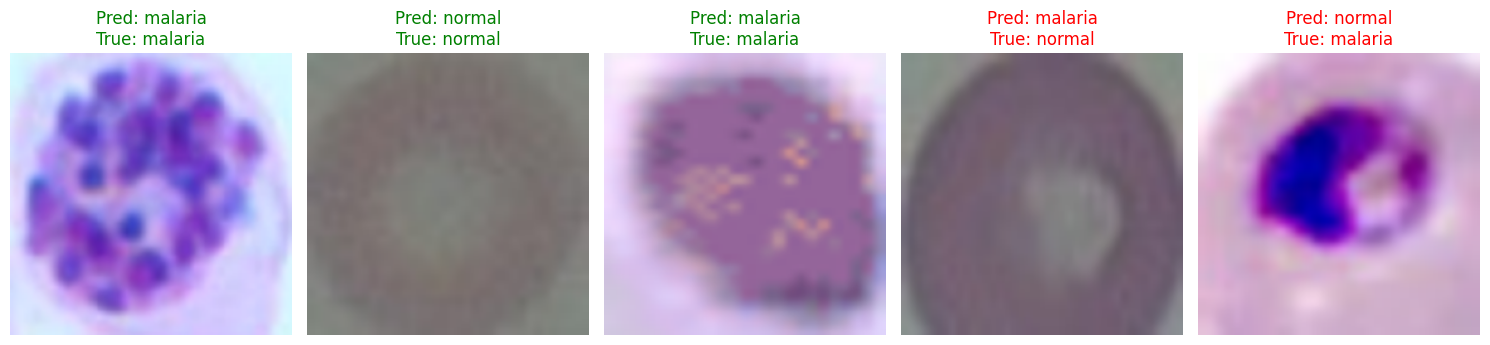

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Data Generator สำหรับการ preprocess รูปภาพก่อนส่งเข้าโมเดล (ไม่ต้อง Augmentation)
test_predict_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # แปลงค่าสีให้เหมาะกับ MobileNet
)

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images_df = test_df.sample(n=5) # ใช้ random_state เพื่อให้ผลลัพธ์ซ้ำเดิมได้

plt.figure(figsize=(15, 6))
for i, row in enumerate(sample_images_df.itertuples()):
    filepath = row.filepath
    true_label = row.label

    # โหลดรูปภาพและปรับขนาด
    img = Image.open(filepath).resize((224, 224))
    # === FIX: Convert image to RGB to ensure 3 channels ===
    img = img.convert('RGB')
    # ==================================================
    img_array = np.array(img) # แปลงเป็น numpy array
    img_array = np.expand_dims(img_array, axis=0) # เพิ่มมิติ batch
    img_array = preprocess_input(img_array) # Preprocess ด้วยฟังก์ชันของ MobileNetV2

    # ทำนายผล
    prediction = model.predict(img_array)
    predicted_class_index = np.argmax(prediction, axis=1)[0]
    # ดึงชื่อคลาสจาก class_names ที่สร้างไว้ก่อนหน้านี้
    predicted_label = class_names[predicted_class_index]

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(img) # แสดงรูปภาพก่อน preprocess สำหรับการมองเห็น
    plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=('green' if predicted_label == true_label else 'red'))
    plt.axis('off')

plt.tight_layout()
plt.show()


#📝 ทดสอบโมเดล

Saving Screenshot 2026-02-19 142404.png to Screenshot 2026-02-19 142404.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


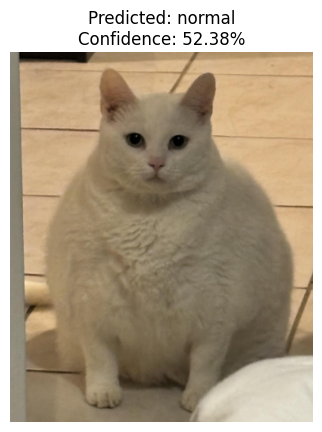

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image

uploaded = files.upload()

for filename in uploaded.keys():
    img = image.load_img(filename, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    predictions = model.predict(img_array)
    class_names = list(train_generator.class_indices.keys())

    idx = np.argmax(predictions[0])
    label = class_names[idx]
    conf = predictions[0][idx] * 100

    plt.imshow(image.load_img(filename))
    plt.title(f"Predicted: {label}\nConfidence: {conf:.2f}%")
    plt.axis('off')
    plt.show()

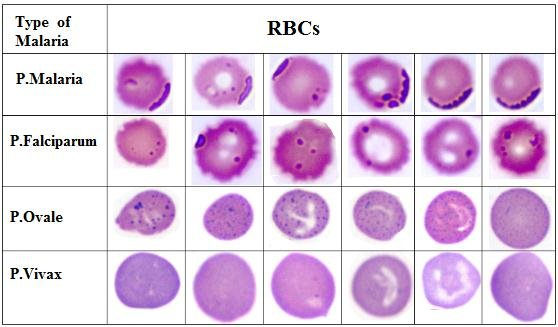